In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # 让 notebooks/ 目录下也能导入 src
from src.rag.retrieval import load_documents, split_documents, build_retriever
from langchain_core.exceptions import OutputParserException
import psycopg
import logging
from typing import Literal, Optional

from langgraph.checkpoint.postgres import PostgresSaver
from langgraph.prebuilt import ToolNode
from langgraph.types import interrupt
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI
import os

from langchain_tavily import TavilySearch
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.constants import START, END
from langgraph.graph import MessagesState, StateGraph
from pydantic import SecretStr, BaseModel, Field, ValidationError, ConfigDict
from dotenv import load_dotenv
import warnings
import logging

                ######################日志##########################
# 1) 统一日志格式 + 级别（让你的 logging.warning 有格式、且 INFO 也可见）
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s %(levelname)s %(name)s %(message)s",
)

# 2) 屏蔽 pydantic 的 UserWarning（注意：这是 warnings 模块，不是 logging）
warnings.filterwarnings("ignore", message=".*PydanticSerializationUnexpectedValue.*")

# 3) 压低 httpx 的 INFO 请求噪声（只保留 WARNING/ERROR，方便定位 API 故障）
logging.getLogger("httpx").setLevel(logging.WARNING)


LOW=60
HIGH=80
LLM_TRY_TIME=5
ERROR_REPORT="服务出现问题请稍后重试"

load_dotenv(verbose=True)
API_KEY = os.getenv("LLM_API_KEY")
#TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")
secretApiKey = SecretStr(API_KEY) if API_KEY else None
#tavily_api_key = SecretStr(API_KEY) if TAVILY_API_KEY else None
BASE_URL = os.getenv("LLM_API_BASE")
MODEL_NAME= os.getenv("LLM_MODEL")
model=ChatOpenAI(
    model=MODEL_NAME if MODEL_NAME else "deepseek-chat",
    api_key=secretApiKey,
    base_url=BASE_URL,
    max_retries=3,
    timeout=5
)
class ReviewResult(BaseModel):
    """
    llm结构化输出内容评分
    """
    model_config = ConfigDict(extra="forbid")
    is_need_evaluate: bool=Field(description="是否需要评审，比如说查天气不需要，生成文章需要,不需要评审的话无需打分无需建议")
    score: int=Field(description="评分0-100",ge=0, le=100)
    feedback:str=Field(description="针对生成内容的建议")


class OverAllState(MessagesState):
    output:str
    context:str
    is_need_evaluate:bool
    score:int
    feedback:str
    human_action:str
    iteration:int
    feedback_source:str
    force_exit:bool

#searchTool=TavilySearch(max_results=5,tavily_api_key=tavily_api_key)
def init(state:OverAllState)->OverAllState:
    return {
        "iteration":0,
        "force_exit":False
    }
DOCS_DIR = os.getenv("DOCS_DIR")
# 2) 检索器构建一次（模块级单例），节点内只 search
_RETRIEVER = None
def get_retriever():
    global _RETRIEVER
    if _RETRIEVER is None:
        docs = load_documents(DOCS_DIR)        # 来自 rag.py
        chunks = split_documents(docs)
        _RETRIEVER = build_retriever(chunks)
    return _RETRIEVER

# 3) 独立 retrieve 节点（generate 之前）
def retrieve(state:OverAllState):
    query = state["messages"][-1].content
    hits = get_retriever().search(query, top_k=3)
    ctx = "\n\n".join(f"[来源:{c['source']}]\n{c['text']}" for c, _ in hits)
    return {"context": ctx}

def generate(state:OverAllState)->OverAllState:
    iteration=state["iteration"]
    if iteration==0:
        messages=state["messages"]
        ctx = state.get("context", "")
        prompt = (f"参考以下资料作答：\n{ctx}\n\n用户需求：{messages}") if ctx else messages
        res=model.invoke(prompt)
        return {
            "messages": res,
            "iteration": iteration + 1,
            "output":res.content
        }
    src = state.get("feedback_source", "ai")
    src_cn = "评审模型" if src == "ai" else "人工审核"
    instruction = HumanMessage(content=(
        f"以下是{src_cn}给出的修改意见，请据此修订你之前的草稿{state["output"]}，"
        f"输出【完整的新版本】，不要只给片段或 diff：\n\n"
        f"{state['feedback']}"
    ))
    res = model.invoke(state["messages"] + [instruction])
    return {
        "messages": [instruction, res],  # 反馈指令 + 新草稿 一并追加进历史
        "iteration": iteration + 1,
        "output":res.content
    }

def evaluate(state:OverAllState)->OverAllState:
    draft=state["output"]
    for attempt in range(LLM_TRY_TIME):
        try:
            result=(model.with_structured_output(ReviewResult)
                    .invoke(f"判断内容是否需要进行评审，如果需要对内容打分(0-100)并且给建议：\n{draft}"))
            return {
                "is_need_evaluate":result.is_need_evaluate,
                "score":result.score,
                "feedback":result.feedback,
                "feedback_source":"ai"
            }
        except (ValidationError, OutputParserException) as e:
            logging.warning("evaluate 解析失败(第%d次): %s", attempt + 1, e)
        except Exception as e:
            logging.warning("evaluate 调用失败(第%d次): %s", attempt + 1, e)
    return {
        "force_exit":True,
        "output":ERROR_REPORT
    }


def route_tool(state: OverAllState) -> str:
    if state["messages"][-1].tool_calls:
        return "tool_node"
    return "evaluate"

def route_review(state: OverAllState) -> str:
    if state["force_exit"]:
        return "end"
    if not state["is_need_evaluate"]:
        return "end"
    if state["iteration"]>=10:
        return "end"
    if state["score"] >= HIGH:
        return "end"
    if state["score"] >= LOW:
        return "regenerate"
    return "human"


class HumanDecision(BaseModel):
    action: Literal["accept", "revise"]          # 只允许这两个值
    feedback: Optional[str] = Field(default=None)  # 打回时必填
def human_review(state: OverAllState):
    error = None
    while True:
        payload = {
            "draft": state["output"],
            "score": state["score"],
            "feedback": state["feedback"],
            "error": error,          # 上一次非法时，把提示带回去
        }
        raw = interrupt(payload)     # 暂停，等人工提交

        try:
            decision = HumanDecision.model_validate(raw)
        except ValidationError as e:
            error = f"输入不合法：{e.errors()}"
            continue                 # 不合法 → 再 interrupt 一次，人工重填

        # 业务约束：打回必须写意见
        if decision.action == "revise" and not decision.feedback:
            error = "选择打回时必须填写修改意见"
            continue

        break                        # 到这里一定是合法输入

    if decision.action == "accept":
        return {"human_action": "accept"}
    return {
        "human_action": "revise",
        "feedback": decision.feedback,
        "feedback_source": "human"
    }

def after_human(state: OverAllState) -> str:
    return "accept" if state["human_action"] == "accept" else "revise"

tools=[]
b=StateGraph(state_schema=OverAllState)
b.add_node("init",init)
b.add_node("retrieve",retrieve)
b.add_node("generate", generate)
b.add_node("evaluate", evaluate)
b.add_node("tool_node", ToolNode(tools=tools))
b.add_node("human_review", human_review)
b.add_edge(START, "init")
b.add_edge("init", "retrieve")
b.add_edge("retrieve", "generate")
b.add_conditional_edges("generate", route_tool,
           {"tool_node":"tool_node","evaluate":"evaluate"})

b.add_edge("tool_node", "generate")
b.add_conditional_edges("evaluate", route_review,
                        {"end": END, "regenerate": "generate", "human": "human_review"})
b.add_conditional_edges("human_review", after_human,
                        {"accept": END, "revise": "generate"})
DB_URL=os.getenv("DB_URL")
conn = psycopg.connect(DB_URL, autocommit=True)   # 手动持有连接
checkpointer = PostgresSaver(conn)
checkpointer.setup()
graph=b.compile(checkpointer=checkpointer)
config={
    "configurable":{
        "thread_id":1
    }
}

In [3]:
print("AI：", end="", flush=True)
for chunk in graph.stream(
    {"messages": [HumanMessage("梧州天气怎么样")]},
    config=config,
    stream_mode="messages"
):
    msg, meta = chunk
    if msg.content:
        token = msg.content
        print(token, end="", flush=True)
print("\n")


AI：

2026-08-26 10:46:28,272 INFO openai._base_client Retrying request to /chat/completions in 0.404325 seconds




我无法提供实时天气信息哦～你可以打开中国天气网、下载手机天气类APP，或直接搜索“梧州天气预报”获取实时及未来天气数据~{
  "feedback": "无需评审",
  "is_need_evaluate": false,
  "score": 85
}



D:\miniConda\envs\langchain1.2\Lib\site-packages\pydantic\main.py:464: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=ReviewResult(is_need_eval...feedback='无需评审'), input_type=ReviewResult])
  return self.__pydantic_serializer__.to_python(


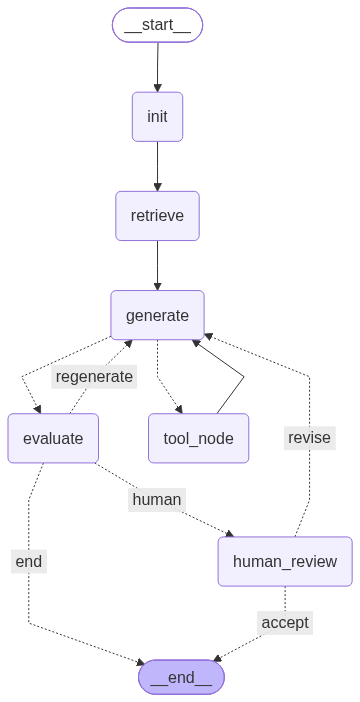

In [2]:
from IPython.display import display
display(graph)

In [4]:
graph.get_state(config)

StateSnapshot(values={'messages': [HumanMessage(content='梧州天气怎么样', additional_kwargs={}, response_metadata={}, id='0d74d08f-77c3-48f9-8889-d16aaee7639f'), AIMessage(content='\n\n我无法提供实时天气信息哦～你可以打开中国天气网、下载手机天气类APP，或直接搜索“梧州天气预报”获取实时及未来天气数据~', additional_kwargs={}, response_metadata={'finish_reason': 'stop', 'model_name': 'agnes-2.0-flash', 'model_provider': 'openai'}, id='lc_run--01a03bf6-2747-7c00-8d12-e7cc31bcabf1', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 287, 'output_tokens': 252, 'total_tokens': 539, 'input_token_details': {'cache_read': 256}, 'output_token_details': {'reasoning': 218}})], 'output': '\n\n我无法提供实时天气信息哦～你可以打开中国天气网、下载手机天气类APP，或直接搜索“梧州天气预报”获取实时及未来天气数据~', 'context': '', 'is_need_evaluate': False, 'score': 85, 'feedback': '无需评审', 'iteration': 1, 'feedback_source': 'ai', 'force_exit': False}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f1a0f85-b1e1-61d3-8004-0219f3e3b89e'}}, metadata={'step': 4, 's